In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
from matplotlib.ticker import FormatStrFormatter
from matplotlib.lines import Line2D

In [2]:
data_sum_nipbl = pd.read_table("NIPBL_data_Sox9.txt")
data_sum_wapl = pd.read_table("WAPL_data_Sox9.txt")
guides = ["NT", "0kb", "98kb", "715kb", "1.2Mb"]
palette=["#83aac3", "#2e4c60", "#ea9648", "#c96d18", "#aed6ca", "#305f51"]

/local/55263823.1.igmm_long/ipykernel_1274054/2099001646.py:12: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  g = sns.stripplot(data=df, y="median", x="guide", hue="treatment", palette=palette,
/local/55263823.1.igmm_long/ipykernel_1274054/2099001646.py:15: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.pointplot(


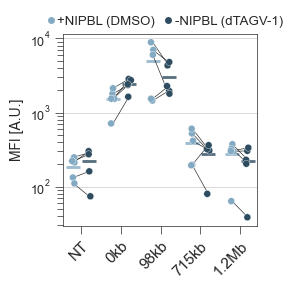

In [3]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.5,2.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

df=data_sum_nipbl

order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "dTAG"]

df=df[df["guide"].isin(order)]

g = sns.stripplot(data=df, y="median", x="guide", hue="treatment", palette=palette,
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5,
                  linewidth=0.25, alpha=1, zorder=10)
sns.pointplot(
    data=df, y="median", x="guide", hue="treatment", palette=palette,
    hue_order=hue_order, order=order, dodge=.4, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=g)

for date in df["rep"].unique():
    dfpiv = df.loc[(df["rep"]==date),["treatment", "median","guide"]].pivot(columns="treatment", values="median", index="guide").reset_index()
    i = 0
    for guide in order:
        if guide in dfpiv["guide"].unique():
            g.plot([i-0.2, i+0.2], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'black', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1

g.set(yscale="log", title="", xlabel="")

g.grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[0], markersize=6, label="+NIPBL (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[1], markersize=6, label="-NIPBL (dTAGV-1)")
]

g.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

plt.xticks(rotation=45, rotation_mode="anchor", ha="right")

g.set_ylabel("MFI [A.U.]", fontsize=10)

g.tick_params(axis='y', labelsize=9)


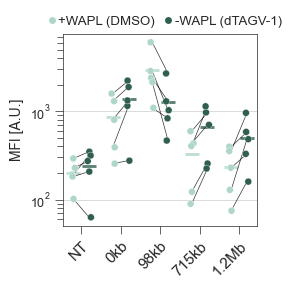

In [4]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.5,2.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

df=data_sum_wapl

order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "dTAG"]

df=df[df["guide"].isin(order)]

g = sns.stripplot(data=df, y="median", x="guide", hue="treatment", palette=palette[4:],
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5,
                  linewidth=0.25, alpha=1, zorder=10)
sns.pointplot(
    data=df, y="median", x="guide", hue="treatment", palette=palette[4:],
    hue_order=hue_order, order=order, dodge=.4, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=g)

for date in df["rep"].unique():
    dfpiv = df.loc[(df["rep"]==date),["treatment", "median","guide"]].pivot(columns="treatment", values="median", index="guide").reset_index()
    i = 0
    for guide in order:
        if guide in dfpiv["guide"].unique():
            g.plot([i-0.2, i+0.2], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'black', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1

g.set(yscale="log", title="", xlabel="")

g.grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[4], markersize=6, label="+WAPL (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[5], markersize=6, label="-WAPL (dTAGV-1)")
]

g.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

g.set_ylabel("MFI [A.U.]", fontsize=10)

plt.xticks(rotation=45, rotation_mode="anchor", ha="right")

g.tick_params(axis='y', labelsize=9)

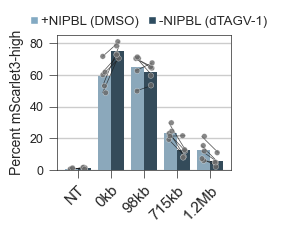

In [5]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.25, 1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})


g = sns.barplot(data=data_sum_nipbl, hue="treatment", x="guide", y="percent_over", order=guides, 
                linewidth=0, palette=palette[0:2], errorbar=None, legend=True)
sns.stripplot(data=data_sum_nipbl, hue="treatment", x="guide", y="percent_over", dodge=True, legend=False, 
              linewidth=0.25, order=guides, palette=["dimgrey"]*2, s=4, alpha=0.8, jitter=0.1, edgecolor="white")
g.set(title="", xlabel="", ylabel="Percent mScarlet3-high")
g.grid(True, axis="y")

handles = [
    Line2D([0], [0], marker='s', color='white',
           markerfacecolor=palette[0], markersize=6, label="+NIPBL (DMSO)"),
    Line2D([0], [0], marker='s', color='white',
           markerfacecolor=palette[1], markersize=6, label="-NIPBL (dTAGV-1)")
]

g.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

for date in data_sum_nipbl["rep"].unique():
    dfpiv = data_sum_nipbl.loc[(data_sum_nipbl["rep"]==date),["treatment", "percent_over","guide"]].pivot(columns="treatment", values="percent_over", index="guide").reset_index()
    i = 0
    for guide in guides:
        if guide in dfpiv["guide"].unique():
            g.plot([i-0.25, i+0.25], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'k', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1
g.set_ylabel("Percent mScarlet3-high", fontsize=10)
plt.xticks(rotation=45, rotation_mode="anchor", ha="right")
g.tick_params(axis='y', labelsize=9)

In [6]:
df = data_sum_nipbl
pval = pd.DataFrame()
for guide in guides:
    x = df.sort_values("rep").loc[(df["guide"] == guide) & (df["treatment"]=="dTAG"), "percent_over"].tolist()
    y = df.sort_values("rep").loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "percent_over"].tolist()
    wc = ttest_rel(x, y, alternative="two-sided") 
    pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x)})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = pval["Guide"] + "_dTAGNIPBL-dTAG / DMSO"
pval["test"] = "ttest_rel"
pval.drop(columns="Guide").sort_values("padj")

,pval,N,padj,sig,log10_p,Condition,test
0,0.010254,5,0.040092,True,1.396939,0kb_dTAGNIPBL-dTAG / DMSO,ttest_rel
0,0.024055,5,0.040092,True,1.396939,715kb_dTAGNIPBL-dTAG / DMSO,ttest_rel
0,0.018095,5,0.040092,True,1.396939,1.2Mb_dTAGNIPBL-dTAG / DMSO,ttest_rel
0,0.131920,5,0.164901,False,0.782778,NT_dTAGNIPBL-dTAG / DMSO,ttest_rel
0,0.408226,5,0.408226,False,0.389100,98kb_dTAGNIPBL-dTAG / DMSO,ttest_rel


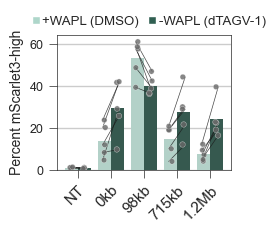

In [7]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.25, 1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})


g = sns.barplot(data=data_sum_wapl, hue="treatment", x="guide", y="percent_over", order=guides, 
                linewidth=0, palette=palette[4:6], errorbar=None, legend=True)
sns.stripplot(data=data_sum_wapl, hue="treatment", x="guide", y="percent_over", dodge=True, legend=False, 
              linewidth=0.25, order=guides, palette=["dimgrey"]*2, s=4, alpha=0.8, jitter=0.1, edgecolor="white")
g.set(title="", xlabel="", ylabel="Percent mScarlet3-high")
g.grid(True, axis="y")
handles = [
    Line2D([0], [0], marker='s', color='white', linewidth=0,
           markerfacecolor=palette[4], markersize=6, label="+WAPL (DMSO)"),
    Line2D([0], [0], marker='s', color='white', linewidth=0,
           markerfacecolor=palette[5], markersize=6, label="-WAPL (dTAGV-1)")
]

g.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

for date in data_sum_wapl["rep"].unique():
    dfpiv = data_sum_wapl.loc[(data_sum_wapl["rep"]==date),["treatment", "percent_over","guide"]].pivot(columns="treatment", values="percent_over", index="guide").reset_index()
    i = 0
    for guide in guides:
        if guide in dfpiv["guide"].unique():
            g.plot([i-0.25, i+0.25], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'k', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1

g.set_ylabel("Percent mScarlet3-high", fontsize=10)
plt.xticks(rotation=45, rotation_mode="anchor", ha="right")
g.tick_params(axis='y', labelsize=9)

In [8]:
df = data_sum_wapl
pval = pd.DataFrame()
for guide in guides:
    x = df.sort_values("rep").loc[(df["guide"] == guide) & (df["treatment"]=="dTAG"), "percent_over"].tolist()
    y = df.sort_values("rep").loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "percent_over"].tolist()
    wc = ttest_rel(x, y, alternative="two-sided") 
    pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x)})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = pval["Guide"] + "_WAPLdTAG-dTAG / DMSO"
pval["test"] = "ttest_rel"
pval.drop(columns="Guide").sort_values("padj")

,pval,N,padj,sig,log10_p,Condition,test
0,0.017101,5,0.021376,True,1.670070,0kb_WAPLdTAG-dTAG / DMSO,ttest_rel
0,0.014408,5,0.021376,True,1.670070,98kb_WAPLdTAG-dTAG / DMSO,ttest_rel
0,0.009514,5,0.021376,True,1.670070,715kb_WAPLdTAG-dTAG / DMSO,ttest_rel
0,0.006142,5,0.021376,True,1.670070,1.2Mb_WAPLdTAG-dTAG / DMSO,ttest_rel
0,0.779879,5,0.779879,False,0.107973,NT_WAPLdTAG-dTAG / DMSO,ttest_rel
